# Discount & Profitability Analysis

This extension tests whether higher discounts are associated with weaker profitability. The analysis uses grouped profit margin rather than assuming correlation alone proves causation.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_excel('../data/cleaned/sample_-_superstore.xlsx')

## 1. Discount bands

In [2]:
bins=[-0.01,0.10,0.20,0.30,0.40,1.00]
labels=['0-10%','10-20%','20-30%','30-40%','40%+']
df['discount_band']=pd.cut(df['discount'], bins=bins, labels=labels)
summary=(df.groupby('discount_band', observed=False)
           .agg(orders=('order_id','nunique'), sales=('sales','sum'), profit=('profit','sum'), avg_profit=('profit','mean'))
           .reset_index())
summary['profit_margin']=summary['profit']/summary['sales']
summary

,discount_band,orders,sales,profit,avg_profit,profit_margin
0,0-10%,2749,1.160276e+06,335818.5572,66.882804,0.289430
1,10-20%,2469,8.014979e+05,92498.9432,24.613875,0.115408
2,20-30%,214,1.044741e+05,-10513.4456,-45.710633,-0.100632
3,30-40%,212,1.309912e+05,-25477.5119,-108.878256,-0.194498
4,40%+,753,1.292949e+05,-100029.7283,-105.183731,-0.773656


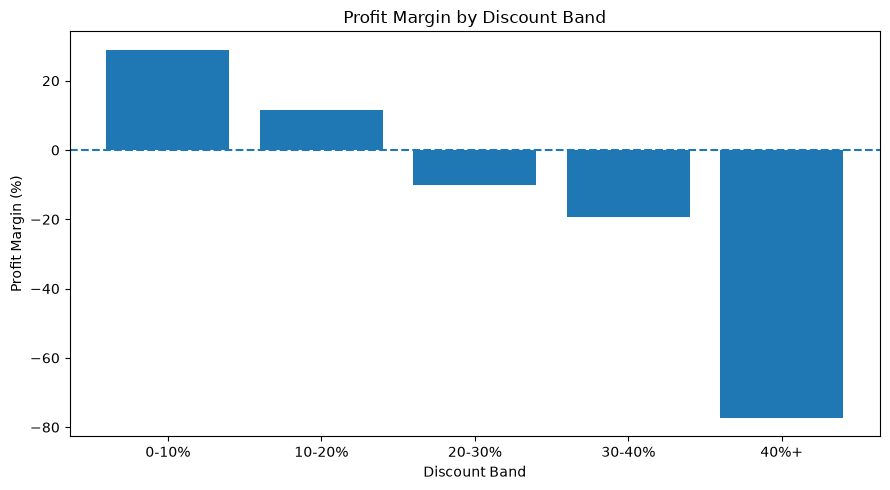

In [3]:
plt.figure(figsize=(9,5))
plt.bar(summary['discount_band'].astype(str), summary['profit_margin']*100)
plt.axhline(0, linestyle='--')
plt.title('Profit Margin by Discount Band')
plt.xlabel('Discount Band')
plt.ylabel('Profit Margin (%)')
plt.tight_layout()
plt.show()

## 2. Business interpretation

Compare sales growth with profit margin across discount bands. A high discount may increase sales while simultaneously reducing profitability; the dashboard should show both metrics.

In [4]:
discount_category=(df.groupby(['category','discount_band'], observed=False)
                          .agg(sales=('sales','sum'),profit=('profit','sum'))
                          .reset_index())
discount_category['profit_margin']=discount_category['profit']/discount_category['sales']
discount_category.sort_values('profit_margin').head(15)

,category,discount_band,sales,profit,profit_margin
9,Office Supplies,40%+,39633.8930,-47224.2558,-1.191512
4,Furniture,40%+,36124.3940,-25590.9243,-0.708411
14,Technology,40%+,53536.5790,-27214.5482,-0.508336
8,Office Supplies,30-40%,79.9740,-29.3238,-0.366667
3,Furniture,30-40%,60107.8648,-18578.5345,-0.309087
2,Furniture,20-30%,100191.1800,-10786.8269,-0.107662
7,Office Supplies,20-30%,526.5820,-52.6582,-0.100000
13,Technology,30-40%,70803.3780,-6869.6536,-0.097024
1,Furniture,10-20%,250951.8695,8027.4892,0.031988
12,Technology,20-30%,3756.3050,326.0395,0.086798


## 3. Conclusion template

Use the actual output rather than a pre-written claim. If higher discount bands show weaker profit margins, the business recommendation is to review discount thresholds by category and product instead of applying blanket discounts.